# Lab 3: Clustering

Welcome to the advanced Machine Learning Course.

The objective of this lab session is to code the agglomerative single Linkage clustering algorithm, and compare it with other methods

Please put **"ML - MDS - TD3"** in the mail subject or I might lose your work (which means 0) and send it to ludovic.trautmann@inria.fr

Please label your notebook **"L3_familyname1_familyname2.ipynb"**.

Make sure to put comments in your code. **Raw numerical results or plots without comments will have almost no value in the grading. Please make sure to comment yout results.**

In [21]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn.cluster as cluster # all clustering techniques except hdbscan
%matplotlib inline
sns.set_context('poster')
sns.set_color_codes()
plot_kwds = {'alpha' : 0.25, 's' : 80, 'linewidths':0}

We will have two toy datasets to try the different methods:

There are a lot of clustering algorithms to choose from the `sklearn` library. So what clustering algorithms should you be using? It depends.

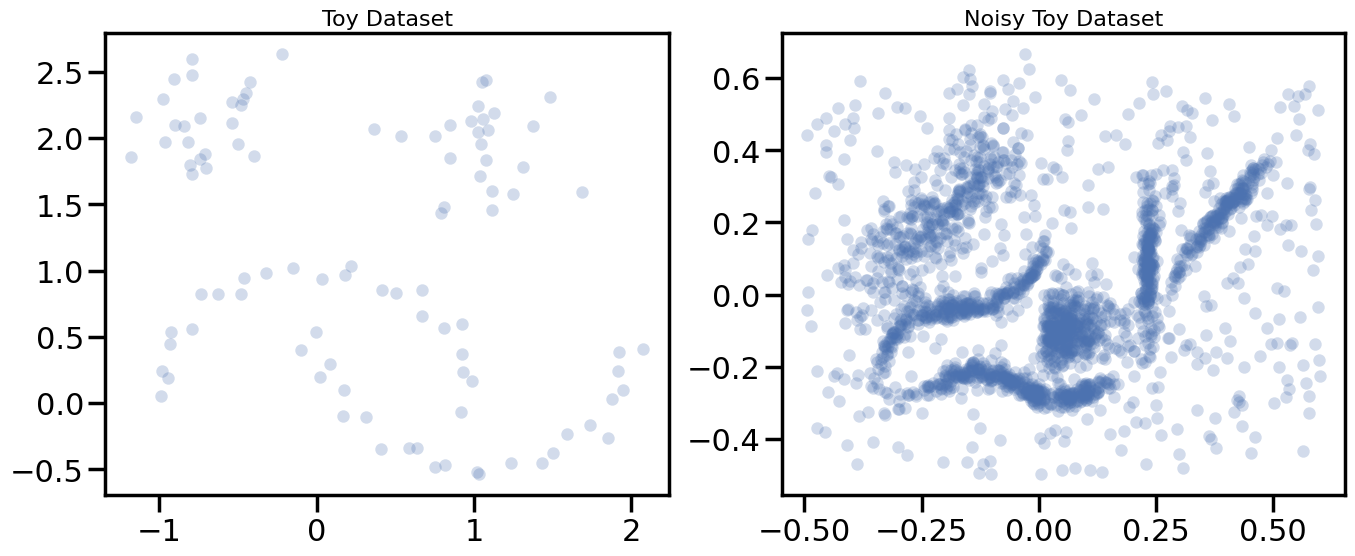

In [22]:
import sklearn.datasets as data
moons, _ = data.make_moons(n_samples=50, noise=0.05)
blobs, _ = data.make_blobs(n_samples=50, centers=[(-0.75,2.25), (1.0, 2.0)], cluster_std=0.25)
test_data_0 = np.vstack([moons, blobs])

test_data_1 = np.load('clusterable_data.npy')

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
ax[0].scatter(test_data_0.T[0], test_data_0.T[1], c='b', **plot_kwds)
ax[0].set_title('Toy Dataset', size=16)

ax[1].scatter(test_data_1.T[0], test_data_1.T[1], color='b', **plot_kwds)
ax[1].set_title('Noisy Toy Dataset', size=16)

plt.show();

## K-means

K-Means is the 'go-to' clustering algorithm for many simply because it is fast, easy to understand, and available everywhere (there's an implementation in almost any statistical or machine learning tool you care to use). However, K-Means has a few problems caused by its simplicity. 

We try the `sklearn` implementation in our toy datasets:

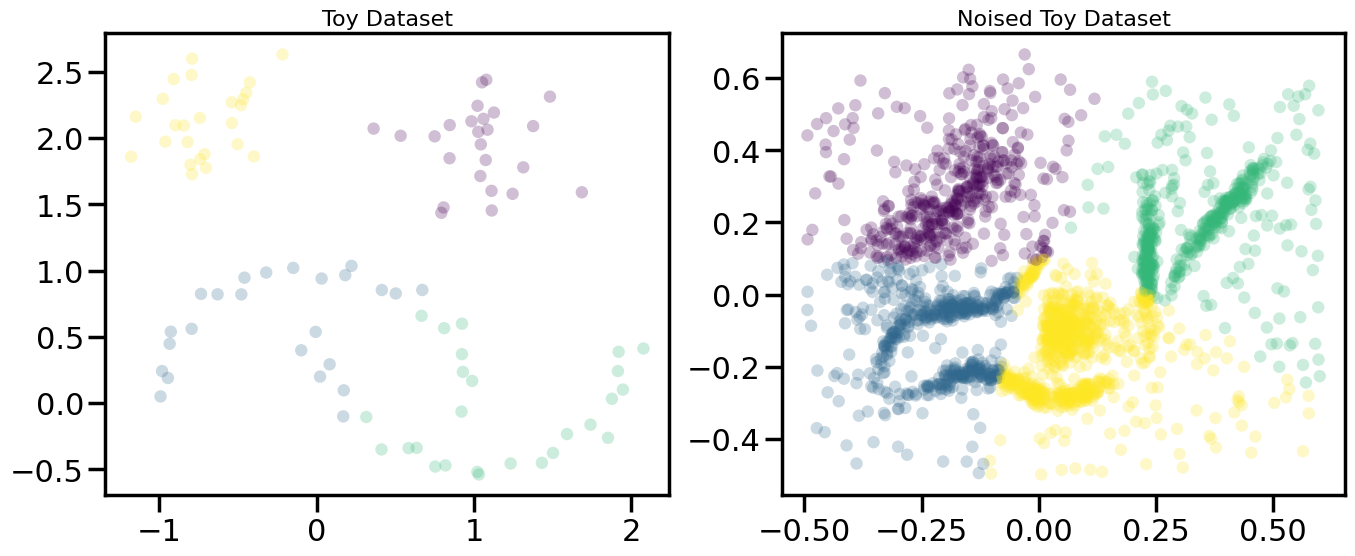

In [23]:
from sklearn.cluster import KMeans
kmeans_0 = KMeans(n_clusters=4, max_iter=200).fit(test_data_0)
kmeans_1 = KMeans(n_clusters=4, max_iter=200).fit(test_data_1)

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
ax[0].scatter(test_data_0.T[0], test_data_0.T[1], c=kmeans_0.labels_ , **plot_kwds)
ax[0].set_title('Toy Dataset', size=16)

ax[1].scatter(test_data_1.T[0], test_data_1.T[1], c=kmeans_1.labels_, **plot_kwds)
ax[1].set_title('Noised Toy Dataset', size=16)


plt.show();

**Comments:** K-means can't capture the form of the expected clusters. It works well for round-shaped clusters (like the ones at the top of the Toy dataset), but for non-convex clusters, the algorithm can't group far-away points. 

## Agglomerative Single Linkage clustering

Agglomerative clustering is a suite of algorithms all based on the same idea. The fundamental idea is that you start with each point in it's own cluster and then, for each cluster, use some criterion to choose another cluster to merge with. Do this repeatedly until you have only one cluster and you get get a hierarchy, or binary tree, of clusters branching down to the last layer which has a leaf for each point in the dataset. The most basic version of this, single linkage, chooses the closest cluster to merge, and hence the tree can be ranked by distance as to when clusters merged/split.

**Code your own Agglomerative Single Linkage clustering algorithm**!:

- Fill in the class 
- During the process, keep track of the cluster merges by saving a (num_samples-1,4) np.array being a linkage matrix in scypy format (to use their function to plot dendrogram: `scipy.cluster.hierarchy.dendrogram`). check documentation.

In [24]:
from scipy.spatial import distance 
from scipy.cluster import hierarchy
from tqdm import tqdm

class my_SingleLinkageAgglomerativeClustering():
    
    def __init__(self, n_clusters=3):
        '''
        Attributes:
        
        n_clusters: integer
            number of clusters to return 
        linkage_matrix_: (n-1, 4) np.array
            in the same format as linkage (check documentation for scipy.cluster.hierarchy.linkage)  
        hierarchy_: list of np.array
            each array corresponds to label assigment
            at each level (number of clusters)
            hierarchy_[0]=np.array(list(range(n)))
        labels_: integer np.array
            label assignement
        '''
        self.n_clusters_ = n_clusters
        self.linkage_matrix_ = None
        self.labels_ = None
        self.hierarchy_ = None
        
    def fit(self, X):
        """ Create a hierarchy of clusters
        
        Parameters:
        -----------
        X: (n, p) np.array
            Data matrix
        
        Note:
        -----
        Updates self.linkage_matrix, self.labels and self.hierarchy
        """

        #TODO

        # Compute the distance matrix using from scipy.spatial import distance 
        
        # HINT:
        # Modify the distance matrix (ex: add row/column for new clusters and remove/put zero in old row/colums)
        # or you can use a minimum spanning tree and add merge in increasing order
        # or something else !
        
        # keep track of merges in linkage_matrix_ and labels in hierarchy_
        
        # update labels_ from the hierarchy level selected by n_clusters_ 
        
        # Initialization 
        n = len(X)
        distance_matrix = distance.cdist(X, X)
        
        self.hierarchy_ = [np.array(list(range(n)))]
        
        for k in tqdm(range(n-1)) :
            # find indexes for which the distance is minimal
            indices = np.argwhere(distance_matrix > 0)
            dist = distance_matrix[distance_matrix > 0]
            
            i, j = indices[np.argmin(dist)]
        
            distance_min = distance_matrix[i, j]
            
            if i < n: 
                nb_original_obs_in_i = 1
            else :
                nb_original_obs_in_i = self.linkage_matrix_[i-n, 3]
            if j < n: 
                nb_original_obs_in_j = 1
            else :
                nb_original_obs_in_j = self.linkage_matrix_[j-n, 3]
            nb_original_obs = nb_original_obs_in_i + nb_original_obs_in_j
            new_row = [i, j, distance_min, nb_original_obs]
            
            if self.linkage_matrix_ is None : 
                self.linkage_matrix_ = new_row
            else: 
                self.linkage_matrix_ = np.vstack((self.linkage_matrix_, new_row))
            
            new_distances = [min(distance_matrix[i, l], distance_matrix[j, l]) for l in range(n + k)]
            
            distance_matrix[i, :] = 0
            distance_matrix[:, i] = 0
            distance_matrix[j, :] = 0
            distance_matrix[:, j] = 0

            distance_matrix = np.vstack((distance_matrix, np.zeros(distance_matrix.shape[1])))
            distance_matrix = np.hstack((distance_matrix, np.zeros((distance_matrix.shape[0], 1))))
            distance_matrix[-1, :-1] = new_distances
            distance_matrix[:-1, -1] = new_distances
            
            self.hierarchy_.append([])
            self.hierarchy_[k + 1] = np.where((self.hierarchy_[k] == i) | (self.hierarchy_[k] == j), n + k, self.hierarchy_[k])
        
        self.labels_ = self.hierarchy_[n - self.n_clusters_]
        
    def plot_dendrogram(self):
        '''Use self.linkage_matrix_ in `scipy.cluster.hierarchy.dendrogram` 
        to plot the dendrogram of the hierarchical structure
        '''

        #TODO    
        hierarchy.dendrogram(self.linkage_matrix_)
        

Apply the method to our toy datasets

100%|██████████| 99/99 [00:00<00:00, 2244.57it/s]


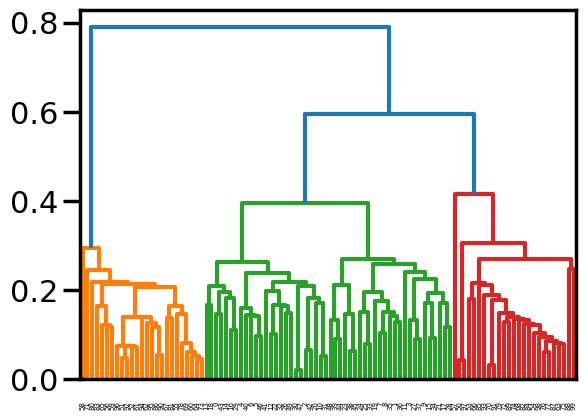

In [25]:
from scipy.spatial import distance 
from scipy.cluster.hierarchy import dendrogram

# TODO
test_data_0 = np.vstack([moons, blobs])
test_data_1 = np.load('clusterable_data.npy')

agglo_clustering = my_SingleLinkageAgglomerativeClustering()
agglo_clustering.fit(test_data_0)
agglo_clustering.plot_dendrogram()

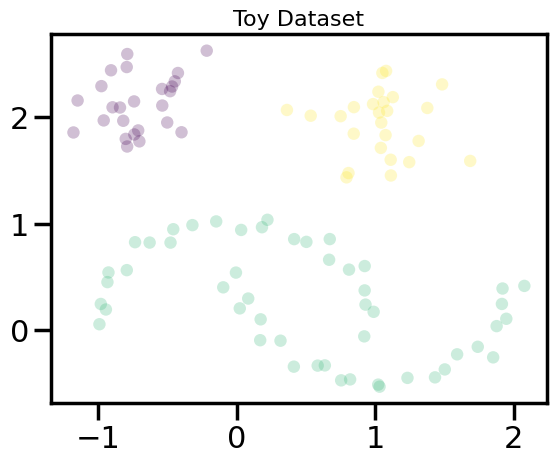

In [27]:

plt.scatter(test_data_0.T[0], test_data_0.T[1], c=agglo_clustering.labels_ , **plot_kwds)
plt.title('Toy Dataset', size=16)

plt.show();

**Comments:**  The 3 clusters detectec match what we could have expected when we decided to compute three clusters. The 2 intertwined clusters at the bottom of the space were merged, while the 2 distincts are the top stay separated. 

  0%|          | 0/2308 [00:00<?, ?it/s]

100%|██████████| 2308/2308 [06:55<00:00,  5.55it/s]


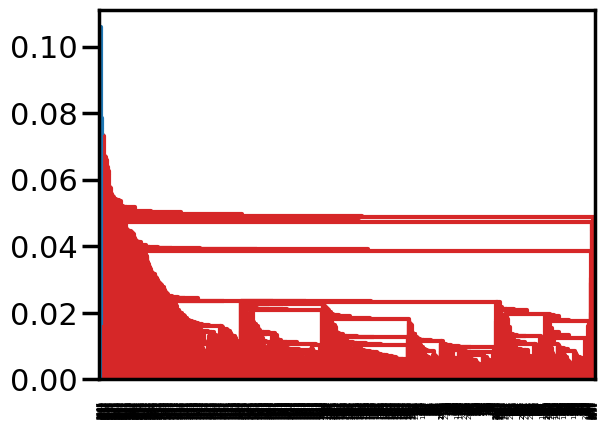

In [28]:
agglo_clustering_1 = my_SingleLinkageAgglomerativeClustering()
agglo_clustering_1.fit(test_data_1)
agglo_clustering_1.plot_dendrogram()

In [ ]:
agglo_clustering_1.labels_[agglo_clustering_1.labels_ == 4604] = 3200
# we changed the label to change the color in the plot, because it was too close of the main color so we couldn't distinguish the cluster

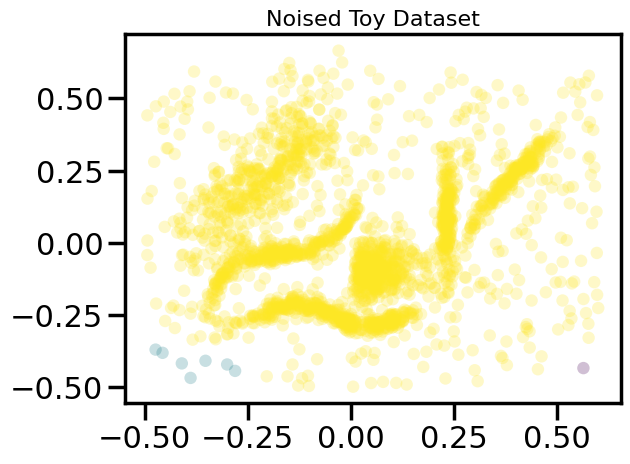

In [34]:
plt.scatter(test_data_1.T[0], test_data_1.T[1], c=agglo_clustering_1.labels_ , **plot_kwds)
plt.title('Noised Toy Dataset', size=16)

plt.show();

**Comments:** The dendrogram mainly identifies 1 cluster: only 8 points don't belong to this cluster. This explain the only color that dominates the dendrogram. 
This method doesn't work on this kind of data: points are too close and data are intertwined.

Try the different linkage methods implemented in `sklearn`  and comment

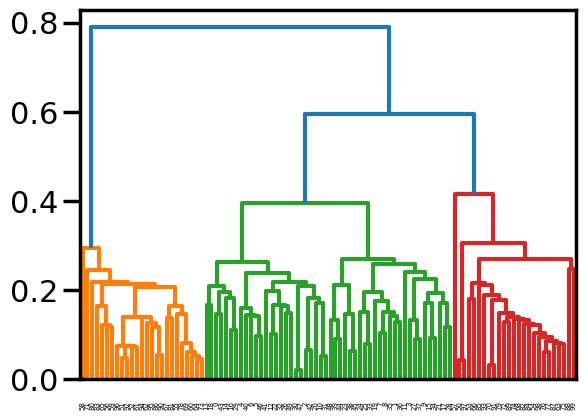

In [38]:
from scipy.cluster.hierarchy import linkage

# TODO
L = linkage(test_data_0)
d = dendrogram(L)

**Comments:** Same dendrogram as the one we get with our code

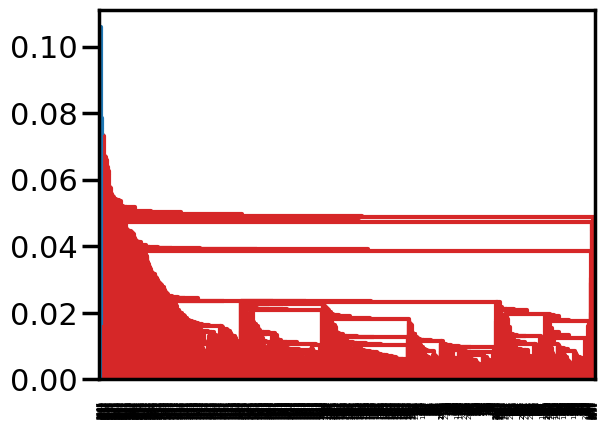

In [42]:
L = linkage(test_data_1)
d = dendrogram(L)

**Comments:** Same dendrogram as the one we get with our code

## DBSCAN

DBSCAN is a density based algorithm -- it assumes clusters for dense regions. It is also the first actual clustering algorithm we've looked at: it doesn't require that every point be assigned to a cluster and hence doesn't partition the data, but instead extracts the 'dense' clusters and leaves sparse background classified as 'noise'. In practice DBSCAN is related to agglomerative clustering. As a first step DBSCAN transforms the space according to the density of the data: points in dense regions are left alone, while points in sparse regions are moved further away. Applying single linkage clustering to the transformed space results in a dendrogram, which we cut according to a distance parameter (called epsilon or `eps` in many implementations) to get clusters. Importantly any singleton clusters at that cut level are deemed to be 'noise' and left unclustered. 

Apply it to the test_data, how do you tune the parameters?

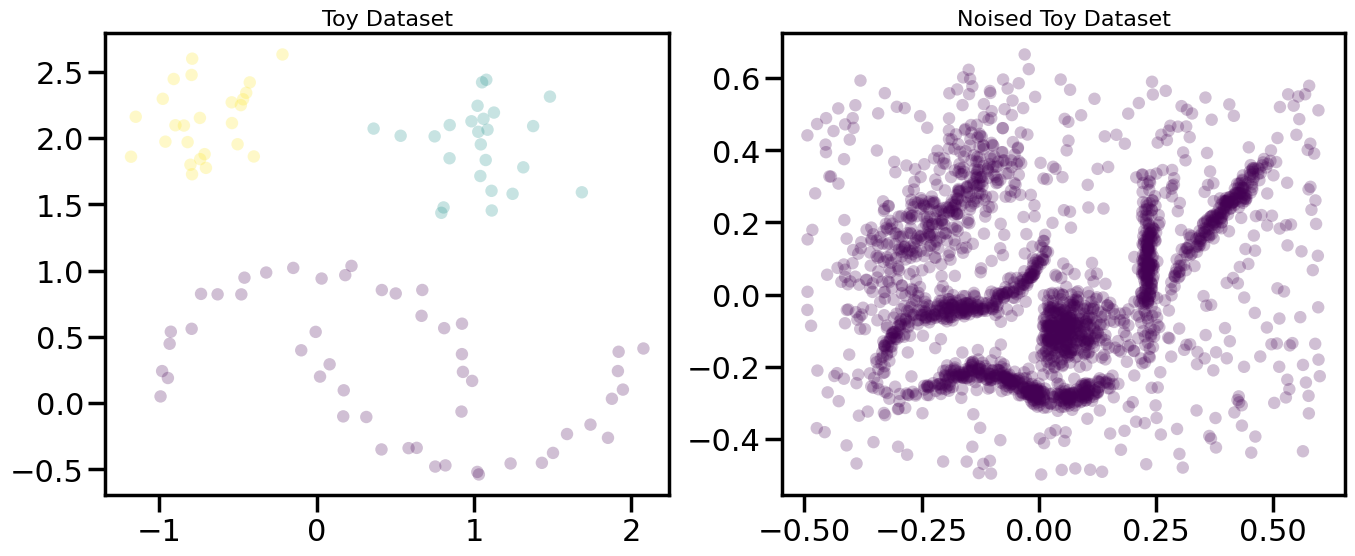

In [43]:
from sklearn.cluster import DBSCAN

# TODO
dbscan_0 = DBSCAN().fit(test_data_0) # default parameters
dbscan_1 = DBSCAN().fit(test_data_1)

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
ax[0].scatter(test_data_0.T[0], test_data_0.T[1], c=dbscan_0.labels_ , **plot_kwds)
ax[0].set_title('Toy Dataset', size=16)

ax[1].scatter(test_data_1.T[0], test_data_1.T[1], c=dbscan_1.labels_, **plot_kwds)
ax[1].set_title('Noised Toy Dataset', size=16)


plt.show();

**Comments:** With default parameters, DBSCAN identifies 3 clusters with the Toy dataset, but only one cluster in the noised toy dataset. 
Indeed, in the toy dataset, dense regions are clearly separated by sparse (even empyty) regions. But it is not the case anymore in the noisy dataset. Now, every region of the space contains datapoints, even though the density varies. 

We will have to adjust the parameters eps and min_samples.

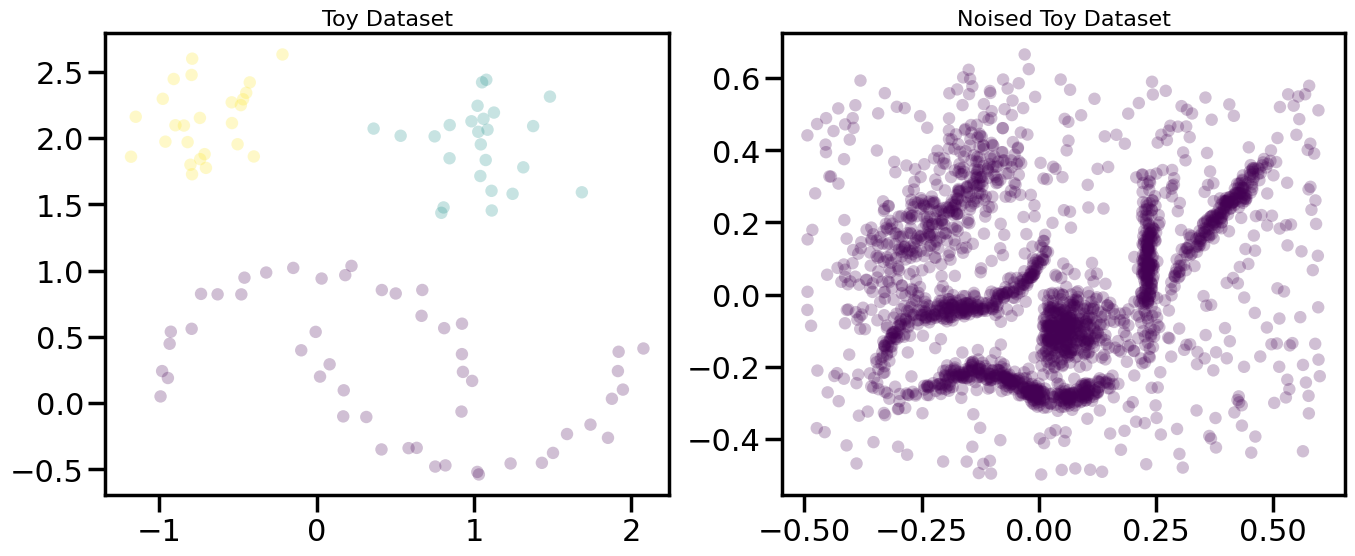

In [46]:
eps = 0.5
min_samples = 6

dbscan_0 = DBSCAN(eps = eps, min_samples = min_samples).fit(test_data_0) # default parameters
dbscan_1 = DBSCAN(eps = eps, min_samples = min_samples).fit(test_data_1)

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
ax[0].scatter(test_data_0.T[0], test_data_0.T[1], c=dbscan_0.labels_ , **plot_kwds)
ax[0].set_title('Toy Dataset', size=16)

ax[1].scatter(test_data_1.T[0], test_data_1.T[1], c=dbscan_1.labels_, **plot_kwds)
ax[1].set_title('Noised Toy Dataset', size=16)


plt.show();

In [49]:
# Finding right parameters for Toy Dataset
epsilon = [0.1*i for i in range(1, 51)]
min_samples = [i for i in range(1, 101)]

nb_clusters_0 = np.zeros((len(min_samples), len(epsilon)))

for a, e in enumerate(epsilon): 
    for b, m in enumerate(min_samples): 
        dbscan_0 = DBSCAN(eps = e, min_samples = m).fit(test_data_0)
        nb_clusters_0[b, a] = len(np.unique(dbscan_0.labels_[dbscan_0.labels_ >=0])) # because label = -1 means the datapoint is considered as 


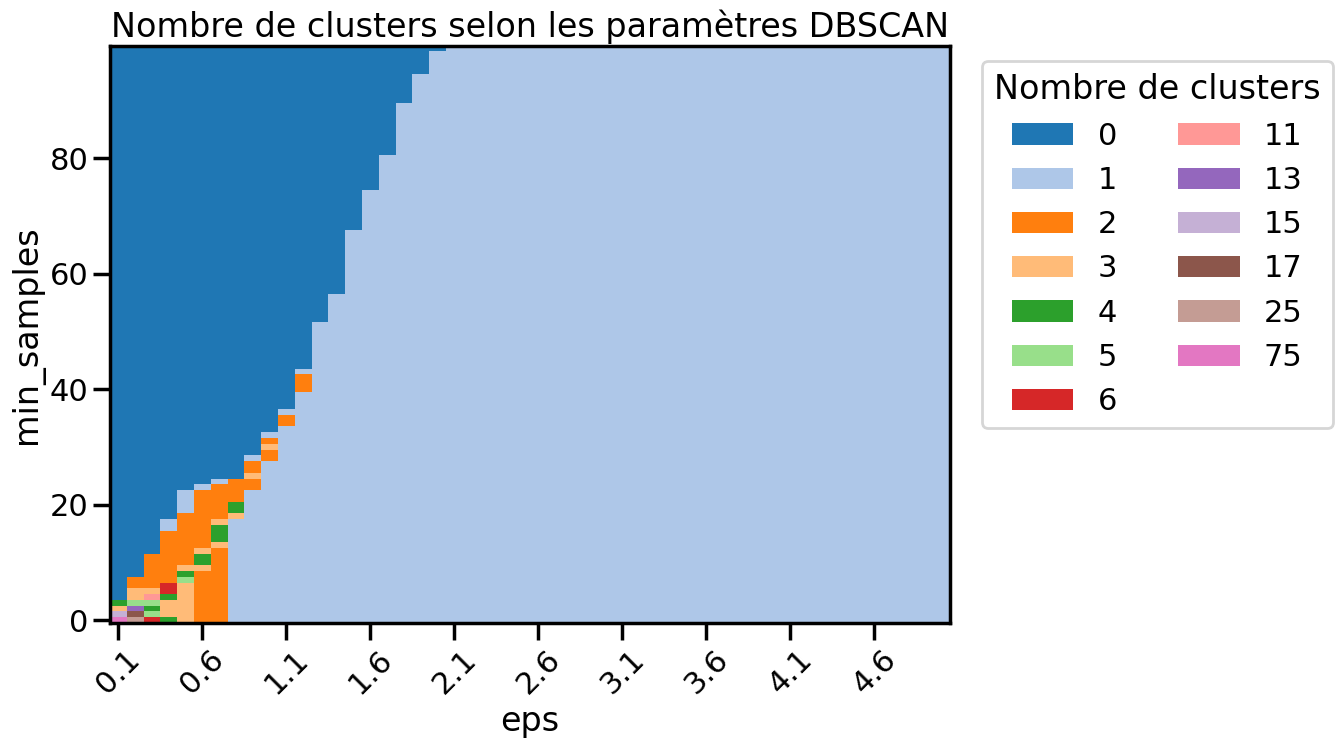

In [48]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

clusters_presents = np.sort(np.unique(nb_clusters_0).astype(int))
n = len(clusters_presents)

# Palette avec des couleurs distinctes
base_colors = plt.get_cmap("tab20").colors
if n <= len(base_colors):
    colors = base_colors[:n]
else:
    colors = plt.get_cmap("gist_ncar", n).colors

# Associer une couleur à chaque valeur présente
cmap = ListedColormap(colors)
bornes = np.r_[clusters_presents - 0.5, clusters_presents[-1] + 0.5]
norm = BoundaryNorm(bornes, cmap.N)

# Remapper les valeurs vers des indices consécutifs
indices = np.searchsorted(clusters_presents, nb_clusters_0)

fig, ax = plt.subplots(figsize=(14, 8))
ax.imshow(indices, origin="lower", aspect="auto",
          interpolation="nearest", cmap=cmap,
          vmin=-0.5, vmax=n - 0.5)

ticks = np.arange(0, len(epsilon), 5)
ax.set_xticks(ticks)
ax.set_xticklabels([f"{epsilon[i]:.1f}" for i in ticks], rotation=45)


ax.set_xlabel("eps")
ax.set_ylabel("min_samples")
ax.set_title("Nombre de clusters selon les paramètres DBSCAN")

# Légende contenant uniquement les valeurs présentes
legend_elements = [
    Patch(facecolor=colors[k], label=str(v))
    for k, v in enumerate(clusters_presents)
]
ax.legend(handles=legend_elements, title="Nombre de clusters",
          bbox_to_anchor=(1.02, 1), loc="upper left", ncol=2)

plt.tight_layout()
plt.show()

**Comments:** Having 0 cluster means that all data were considered as noise (label = -1). 
With this data, we see that when epsilon and min_samples are too small, we create a lot of clusters that are not representative of the data. 
The defalut values (eps = 0.5 and min_samples = 5 ) already gave 3 clusters : what a human would have detected. 

In [ ]:
epsilon = [0.1*i for i in range(1, 51)]
min_samples = [i for i in range(1, 101)]

nb_clusters_1 = np.zeros((len(min_samples), len(epsilon)))

for a, e in enumerate(epsilon): 
    for b, m in enumerate(min_samples): 
        dbscan_1 = DBSCAN(eps = e, min_samples = m).fit(test_data_1)
        nb_clusters_1[b, a] = len(np.unique(dbscan_1.labels_[dbscan_1.labels_ >=0])) # because label = -1 means the datapoint is considered as 


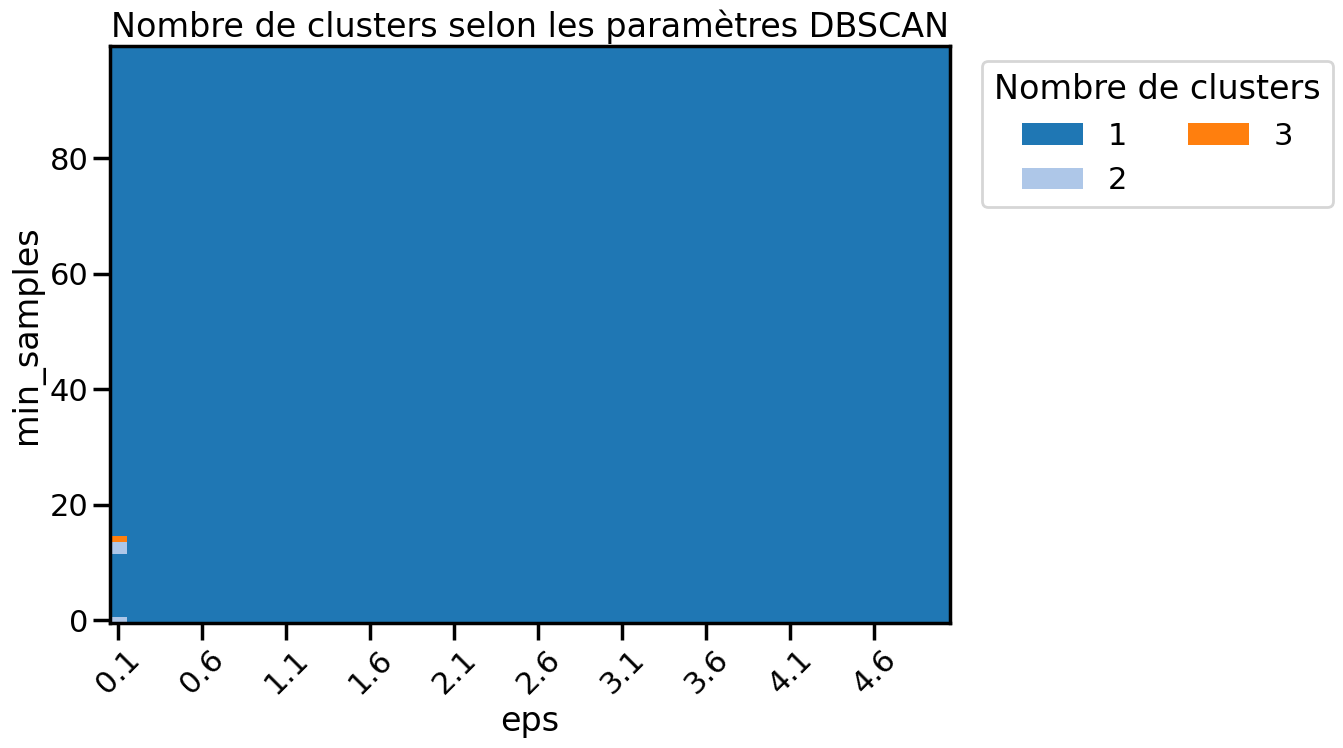

In [ ]:
clusters_presents = np.sort(np.unique(nb_clusters_1).astype(int))
n = len(clusters_presents)

# Palette avec des couleurs distinctes
base_colors = plt.get_cmap("tab20").colors
if n <= len(base_colors):
    colors = base_colors[:n]
else:
    colors = plt.get_cmap("gist_ncar", n).colors

# Associer une couleur à chaque valeur présente
cmap = ListedColormap(colors)
bornes = np.r_[clusters_presents - 0.5, clusters_presents[-1] + 0.5]
norm = BoundaryNorm(bornes, cmap.N)

# Remapper les valeurs vers des indices consécutifs
indices = np.searchsorted(clusters_presents, nb_clusters_1)

fig, ax = plt.subplots(figsize=(14, 8))
ax.imshow(indices, origin="lower", aspect="auto",
          interpolation="nearest", cmap=cmap,
          vmin=-0.5, vmax=n - 0.5)

ticks = np.arange(0, len(epsilon), 5)
ax.set_xticks(ticks)
ax.set_xticklabels([f"{epsilon[i]:.1f}" for i in ticks], rotation=45)

ax.set_xlabel("eps")
ax.set_ylabel("min_samples")
ax.set_title("Nombre de clusters selon les paramètres DBSCAN")

# Légende contenant uniquement les valeurs présentes
legend_elements = [
    Patch(facecolor=colors[k], label=str(v))
    for k, v in enumerate(clusters_presents)
]
ax.legend(handles=legend_elements, title="Nombre de clusters",
          bbox_to_anchor=(1.02, 1), loc="upper left", ncol=2)

plt.tight_layout()
plt.show()

**Comments:** Most of the time, we only get 1 cluster. It is probably because the data is already quite dense, so the model struggle to find appropriate clusters. Now, we will even reduce the values of epsilon to see if we get better results. 

In [ ]:
epsilon = [0.01*i for i in range(1, 21)]
min_samples = [i for i in range(1, 21)]

nb_clusters_1 = np.zeros((len(min_samples), len(epsilon)))

for a, e in enumerate(epsilon): 
    for b, m in enumerate(min_samples): 
        dbscan_1 = DBSCAN(eps = e, min_samples = m).fit(test_data_1)
        nb_clusters_1[b, a] = len(np.unique(dbscan_1.labels_[dbscan_1.labels_ >=0])) # because label = -1 means the datapoint is considered as 


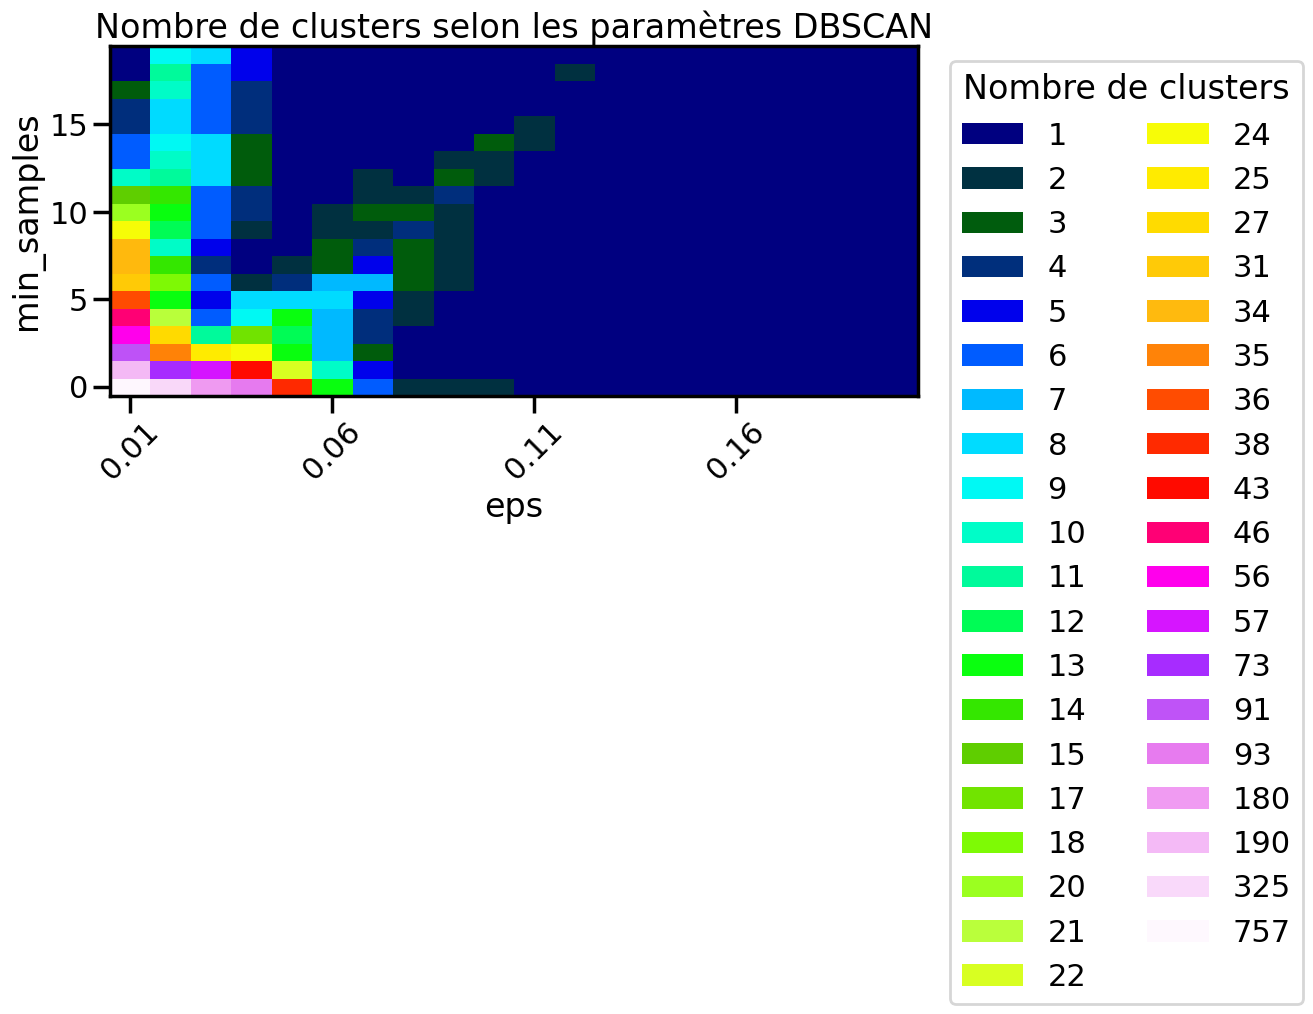

In [ ]:
clusters_presents = np.sort(np.unique(nb_clusters_1).astype(int))
n = len(clusters_presents)

# Palette avec des couleurs distinctes
base_colors = plt.get_cmap("tab20").colors
colors = plt.get_cmap("gist_ncar", n)(
    np.arange(n)
)
# Associer une couleur à chaque valeur présente
cmap = ListedColormap(colors)
bornes = np.r_[clusters_presents - 0.5, clusters_presents[-1] + 0.5]
norm = BoundaryNorm(bornes, cmap.N)

# Remapper les valeurs vers des indices consécutifs
indices = np.searchsorted(clusters_presents, nb_clusters_1)

fig, ax = plt.subplots(figsize=(14, 8))
ax.imshow(indices, origin="lower", aspect="auto",
          interpolation="nearest", cmap=cmap,
          vmin=-0.5, vmax=n - 0.5)

ticks = np.arange(0, len(epsilon), 5)
ax.set_xticks(ticks)
ax.set_xticklabels([f"{epsilon[i]:.2f}" for i in ticks], rotation=45)

ax.set_xlabel("eps")
ax.set_ylabel("min_samples")
ax.set_title("Nombre de clusters selon les paramètres DBSCAN")

# Légende contenant uniquement les valeurs présentes
legend_elements = [
    Patch(facecolor=colors[k], label=str(v))
    for k, v in enumerate(clusters_presents)
]
ax.legend(handles=legend_elements, title="Nombre de clusters",
          bbox_to_anchor=(1.02, 1), loc="upper left", ncol=2)

plt.tight_layout()
plt.show()

**Comments:** Finally, we see more clusters appear. So when the data is dense, we need to choose an epsilon small enough for the model to identify clusters. 

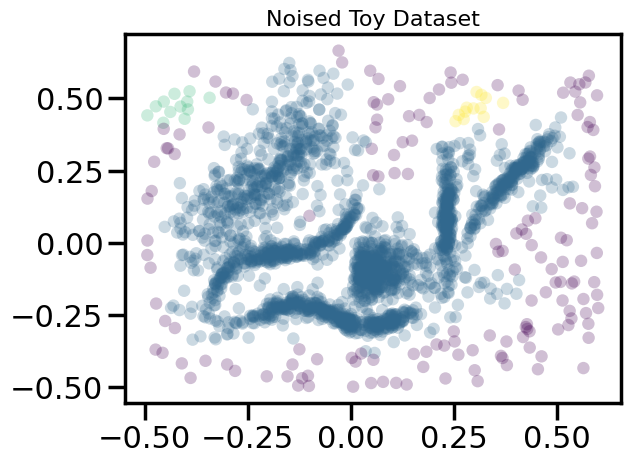

In [51]:
eps = 0.06
min_samples = 9

dbscan_1 = DBSCAN(eps = eps, min_samples = min_samples).fit(test_data_1)

plt.scatter(test_data_1.T[0], test_data_1.T[1], c=dbscan_1.labels_, **plot_kwds)
plt.title('Noised Toy Dataset', size=16)

plt.show();

**Comments:** With this choice of parameters, the model still struggle to identify clusters as a human would do. However, noise is detected properly.

## HDBSCAN

HDBSCAN is a recent algorithm developed by some of the same people who write the original DBSCAN paper. Their goal was to allow varying density clusters. The algorithm starts off much the same as DBSCAN: we transform the space according to density, exactly as DBSCAN does, and perform single linkage clustering on the transformed space. Instead of taking an epsilon value as a cut level for the dendrogram however, a different approach is taken: the dendrogram is condensed by viewing splits that result in a small number of points splitting off as points 'falling out of a cluster'. This results in a smaller tree with fewer clusters that 'lose points'. That tree can then be used to select the most stable or persistent clusters. This process allows the tree to be cut at varying height, picking our varying density clusters based on cluster stability.

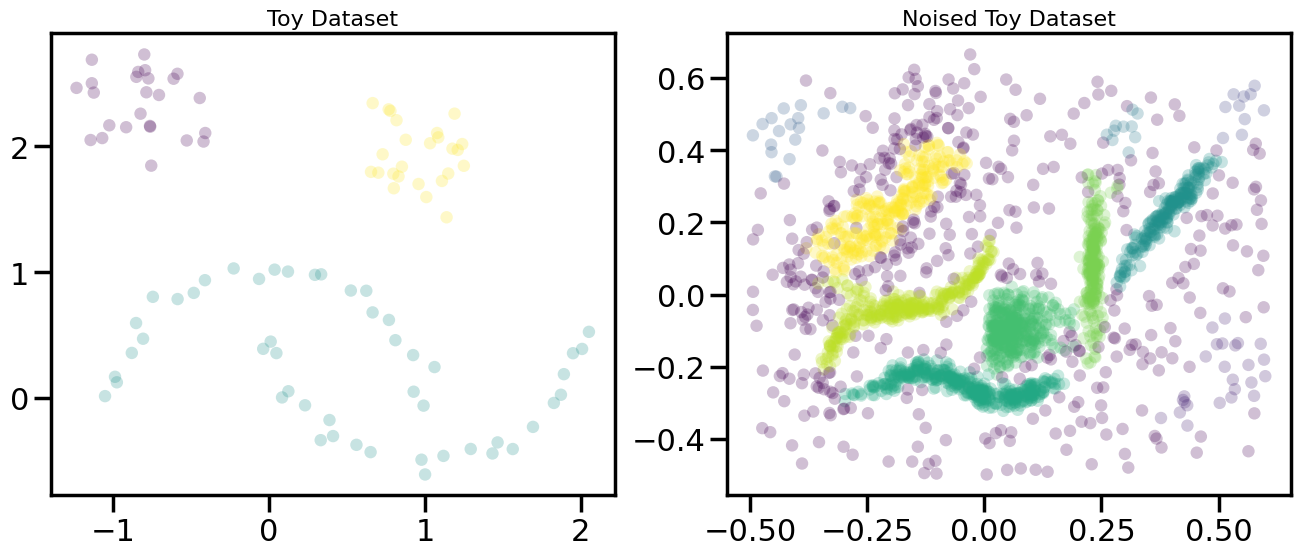

In [ ]:
from sklearn.cluster import HDBSCAN

# TODO
hdbscan_0 = HDBSCAN().fit(test_data_0) # default parameters
hdbscan_1 = HDBSCAN(min_samples=5, min_cluster_size=10).fit(test_data_1)

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
ax[0].scatter(test_data_0.T[0], test_data_0.T[1], c=hdbscan_0.labels_, **plot_kwds)
ax[0].set_title('Toy Dataset', size=16)

ax[1].scatter(test_data_1.T[0], test_data_1.T[1], c=hdbscan_1.labels_, **plot_kwds)
ax[1].set_title('Noised Toy Dataset', size=16)

plt.show();

In [ ]:
print(np.unique(hdbscan_0.labels_))
print(f"Number of cluster on Toy data: {len(np.unique(hdbscan_0.labels_))} (default parameters)")

[0 1 2]
Number of cluster on Toy data: 3 (default parameters)


In [ ]:
print(np.unique(hdbscan_1.labels_))
print(f"Number of cluster on Toy data: {len(np.unique(hdbscan_1.labels_[hdbscan_1.labels_ >=0]))} (default parameters)")

[-1  0  1  2  3  4  5  6  7  8  9]
Number of cluster on Toy data: 10 (default parameters)


Text(0.5, 1.0, 'Noise on Noised Toy Dataset')

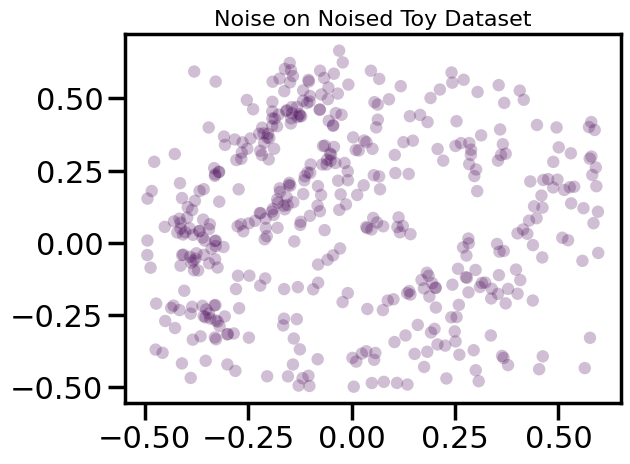

In [ ]:
plt.scatter(test_data_1.T[0][hdbscan_1.labels_ == -1], test_data_1.T[1][hdbscan_1.labels_ == -1], c=hdbscan_1.labels_[hdbscan_1.labels_ == -1], **plot_kwds)
plt.title('Noise on Noised Toy Dataset', size=16)

**Comments:** The model finds appropriate clusters on the Toy Dataset. On the Noised Toy dataset, HDBSCAN also identifies 10 clusters, that are close to what we would expect as human. The purple dots are the ones associated to noise. 

Best performance we had on the noised toy dataset so far! 

## Apply the algorithms to the following images and comment the results

### NASA Curiosity Picture

- Look at following NASA photo taken by a robot in mars:


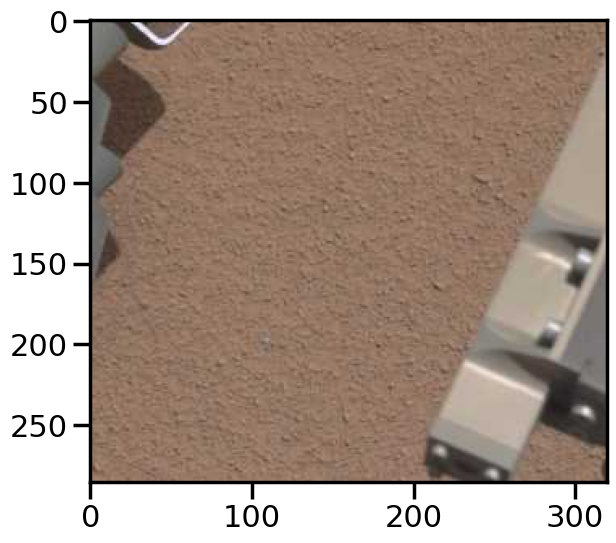

In [ ]:
from PIL import Image

Im_1  = Image.open('im_nasa_reduced.jpg')

fig = plt.figure(figsize=(8, 6))
plt.imshow(Im_1)
plt.show()

- Transform the image to an intensity (I) and saturation (S) representation, it helps to distinguish bright and textures.

$$I=\frac{R+G+B}{3}$$
$$S=1- \frac{min(R, G, B)}{I}$$

**Comments:** After some research online, we realized that we should divide by I and not multiply (source: https://pages.hmc.edu/ruye/e161/lectures/ColorProcessing/node2.html )

In [52]:
rgb = np.array(Im_1.convert("RGB")) /255.0 #normalization to deal with floats

In [53]:
# TODO:

r = rgb[:, :, 0]
g = rgb[:, :, 1]
b = rgb[:, :, 2]
I = (r + g + b)/3
S = 1 -  np.minimum(np.minimum(r, g), b)/I
image_is = np.stack((I, S), axis=-1)

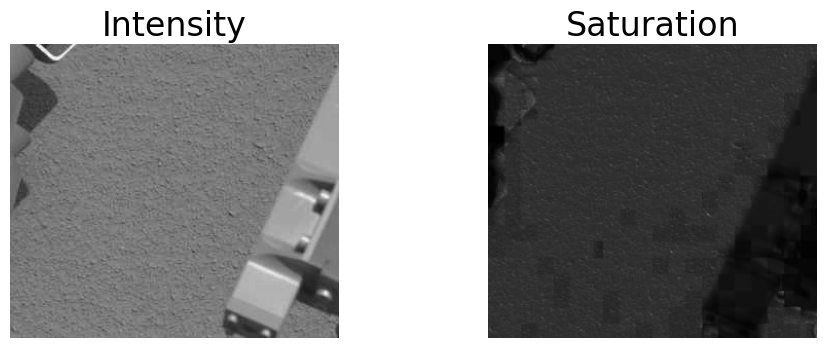

In [54]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].imshow(I, cmap="gray", vmin=0, vmax=1)
ax[0].set_title("Intensity")
ax[1].imshow(S, cmap="gray", vmin=0, vmax=1)
ax[1].set_title("Saturation")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()

- Apply the seen algorithms to segment the image in the Intensity-Saturation representation, comment the results and check if you find something on mars' surface. Be careful with hdbscan and memory errors for some parameters choice (use algorithm='boruvka_kdtree').

In [55]:
# TODO
image_is_flat = image_is.reshape(-1, 2)

#### DBSCAN 

In [56]:
dbscan = DBSCAN(eps=0.03, min_samples=30, n_jobs=-1)
labels_db = dbscan.fit_predict(image_is_flat)

# Revenir à la forme de l'image
seg_db = labels_db.reshape(I.shape)

# Nombre de clusters, sans compter le bruit (-1)
n_clusters_db = len(set(labels_db) - {-1})
n_bruit_db = np.sum(labels_db == -1)

print("Nombre de clusters :", n_clusters_db)
print("Pixels de bruit :", n_bruit_db)
print("Pourcentage de bruit :", 100 * n_bruit_db / len(labels_db))

MemoryError: 

**Comments:** We get a memory error --> image too big, we will try another algorithm. 

#### HDBSCAN

In [ ]:
hdbscan = HDBSCAN(algorithm="kd_tree", min_cluster_size=50).fit(image_is_flat)

labels = hdbscan.labels_
seg_hdb = labels.reshape(I.shape)

n_clusters_hdb = len(set(labels) - {-1})
n_bruit_hdb = np.sum(labels == -1)

print("Nombre de clusters :", n_clusters_hdb)
print("Pixels de bruit :", n_bruit_hdb)
print("Pourcentage de bruit :", 100 * n_bruit_hdb / len(labels))


Nombre de clusters : 214
Pixels de bruit : 15778
Pourcentage de bruit : 17.239947552447553


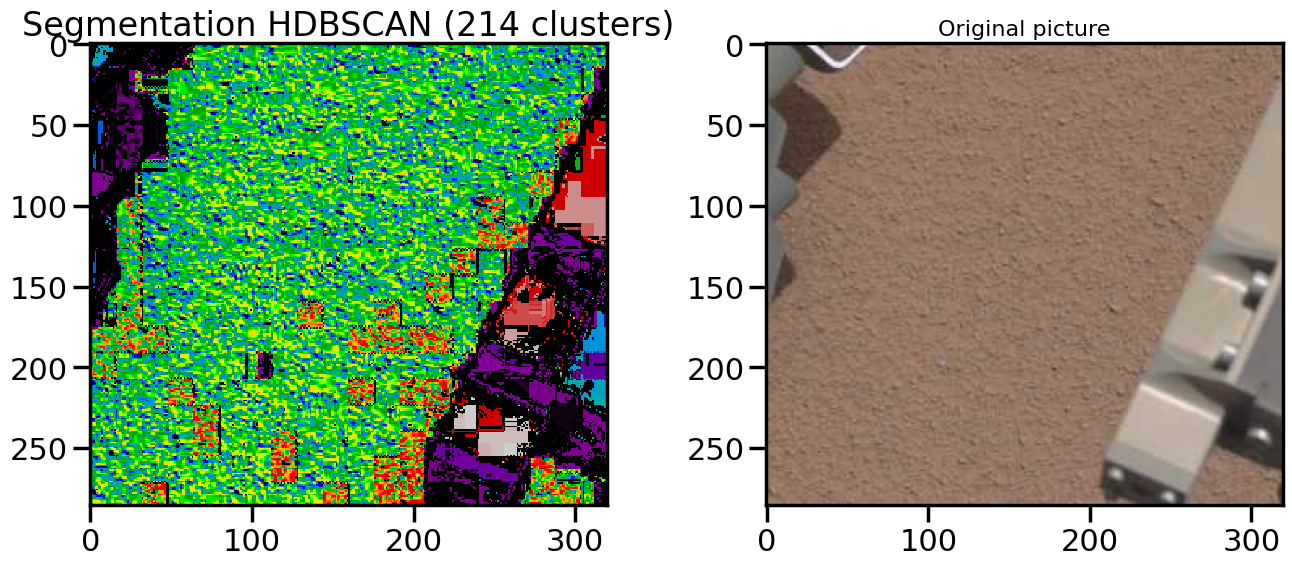

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
ax[0].imshow(seg_hdb, cmap="nipy_spectral", interpolation="nearest")
ax[0].set_title(f"Segmentation HDBSCAN ({n_clusters_hdb} clusters)")

ax[1].imshow(Im_1)
ax[1].set_title('Original picture', size=16)


plt.show();

In [ ]:
import hdbscan
hdbscan_im = hdbscan.HDBSCAN(algorithm="boruvka_kdtree", min_cluster_size=50).fit(image_is_flat)

labels = hdbscan_im.labels_
seg_hdb = labels.reshape(I.shape)

n_clusters_hdb = len(set(labels) - {-1})
n_bruit_hdb = np.sum(labels == -1)

print("Nombre de clusters :", n_clusters_hdb)
print("Pixels de bruit :", n_bruit_hdb)
print("Pourcentage de bruit :", 100 * n_bruit_hdb / len(labels))

Nombre de clusters : 214
Pixels de bruit : 15683
Pourcentage de bruit : 17.136145104895103


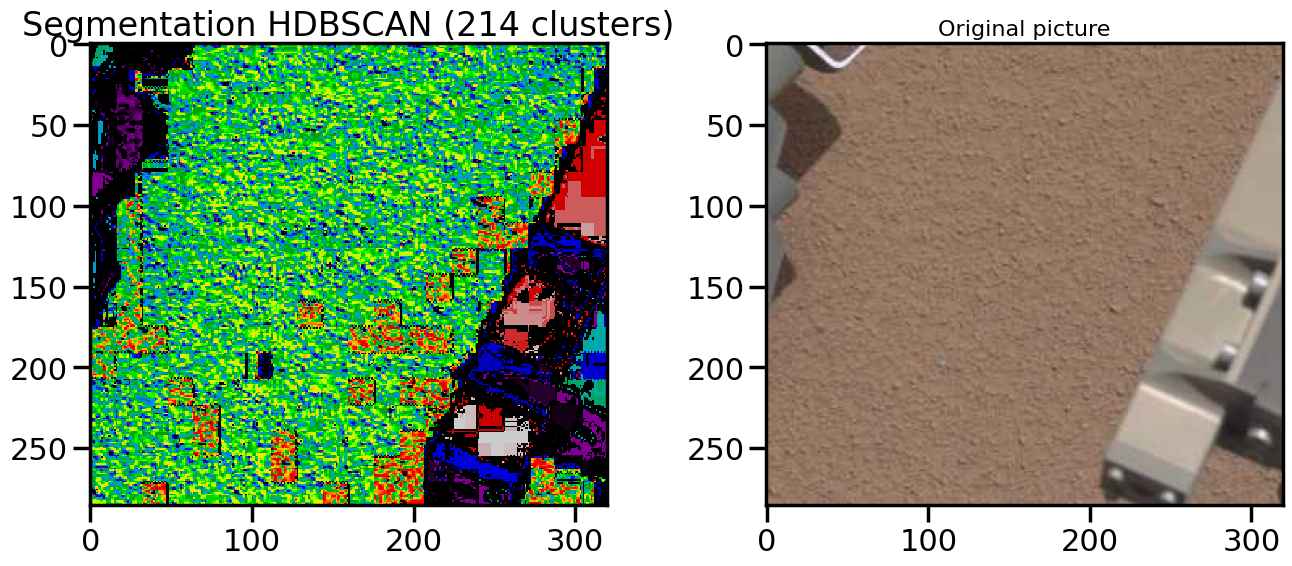

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
ax[0].imshow(seg_hdb, cmap="nipy_spectral", interpolation="nearest")
ax[0].set_title(f"Segmentation HDBSCAN ({n_clusters_hdb} clusters)")

ax[1].imshow(Im_1)
ax[1].set_title('Original picture', size=16)


plt.show();

**Comments:** With both methods (HDBSCAN from sklearn + kd_tree and HDBSCAN from hdbscan + boruvka_kdtree), we get similar results for min_cluster_size=50. It gives 214 clusters, and we plotted the picture with a color code matching the cluster to which the point belongs. 
We detect an anomaly on the ground: a black/purple area, when the rest of the ground is yellow/green/red in the cluster space. This area matches an area of the original picture that is slighlty lighter than the rest. Maybe we detected a object on Mars's surface, but we can't recognize what it is.

### Color compression

One interesting application of clustering is in color compression within images. 
For example, imagine you have an image with millions of colors.
In most images, a large number of the colors will be unused, and many of the pixels in the image will have similar or even identical colors.

Get a simplified 10-colored version of the following image by applying k-means. Plot both images.

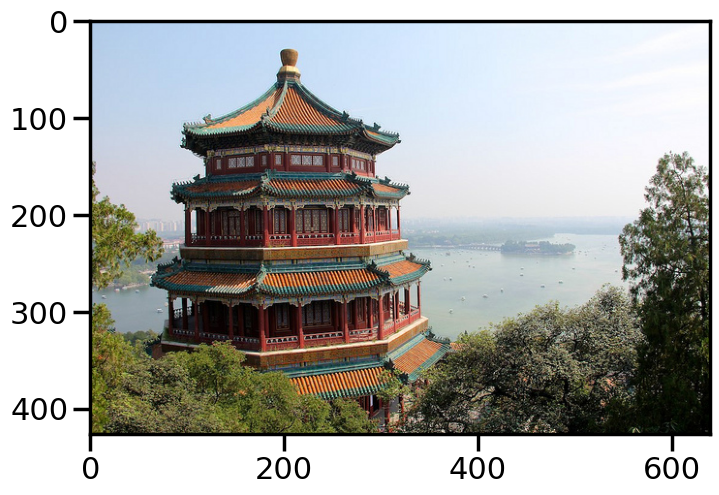

In [58]:
from sklearn.datasets import load_sample_image
china = load_sample_image("china.jpg")

fig = plt.figure(figsize=(8, 6))
plt.imshow(china);

In [59]:
# TODO
china_flat = china.reshape(-1, 3) / 255 # rgb data has to be between 0 and 1 if we want to deal with floats (better suited to work with centroids)

kmeans = KMeans(n_clusters=10, max_iter=200).fit(china_flat)
china_simple = kmeans.cluster_centers_[kmeans.labels_]

china_simple_3d = china_simple.reshape(china.shape)

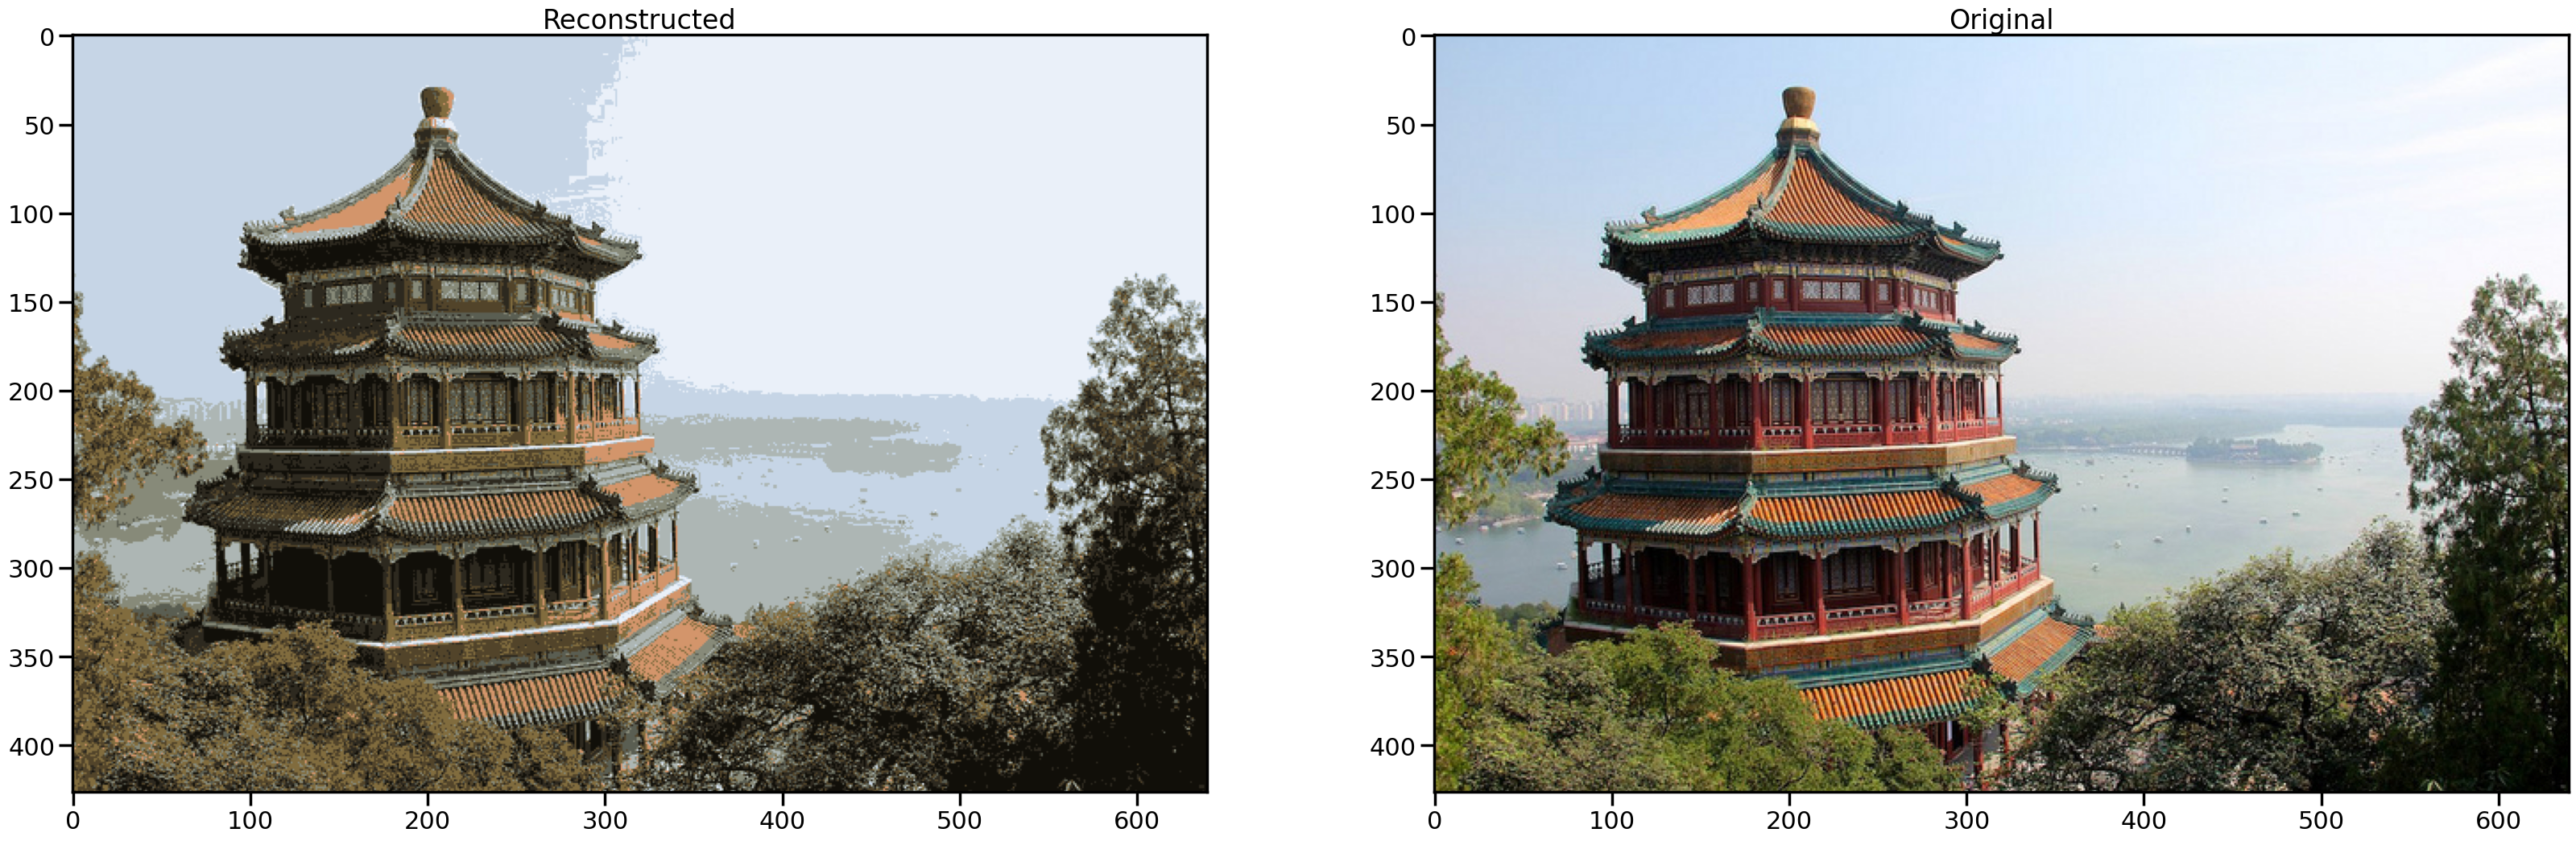

In [60]:
plt.figure(figsize=(40,20))
plt.subplot(1,2,1)
plt.title("Reconstructed")
plt.imshow(china_simple_3d)
plt.subplot(1,2,2)
plt.title("Original")
plt.imshow(china)

**Comments:** The result is quite impressive ! We recognize the different details of the first picture, even though some are a blurred (for example, buildings in the background or the sky). 